# 1. Repair Duration Regression — Model Competition V2

Thực nghiệm hồi quy số phút kỹ thuật chủ động cho Apple Repair Service.
**EXPERIMENTAL — SYNTHETIC-DATA TRAINED — NOT PRODUCTION VALIDATED.**

## 2. Business problem

Cửa hàng cần một ước lượng thời lượng kỹ thuật để hỗ trợ lập ETA và điều phối.
Kết quả mô hình không tự nó là ETA và không tự quyết định phân công.

## 3. ML problem

Với $D=\{(x_i,y_i)\}_{i=1}^{n}$, mô hình hồi quy học
$\hat y_i=f(x_i)$, trong đó $y_i$ là `actual_technical_minutes`.

## 4. Prediction-time definition

Thời điểm dự đoán là assignment đầu tiên sau khi phương án một hạng mục APPROVED
đã biết. Mọi feature phải tồn tại tại hoặc trước thời điểm này.

## 5. Sample grain

Một completed ticket, đúng một approved repair item, một assignment, không
transfer và status history liên tục. Schema hiện không có timer per-item nên
không phân bổ giả thời lượng cho phiếu nhiều hạng mục.

## 6. Target definition

$$y=\frac1{60}\sum_{k:u_k\in\{INSPECTING,REPAIRING\}}
\max(0,\min(e_k,a_e)-\max(s_k,a_s))_{seconds}.$$

Không tính queue, chờ khách, chờ linh kiện, break, transfer gap hay chờ bàn giao.
Persistence interruption hiện chưa được duration service tự trừ.

## 7. Synthetic limitation

V2 dùng controlled synthetic catalog vì repository không có full canonical
master seed. Quan hệ device→model→issue→service hợp lý nhưng không được xem là
record production. Hidden target factors không được xuất ra dataset.

## 8. Imports, seed and library versions

In [1]:
%matplotlib inline
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, catboost

ML_ROOT = Path('ml') if Path('ml').exists() else Path.cwd()
sys.path.insert(0, str((ML_ROOT / 'src').resolve()))
from repair_duration_ml.config import *
from repair_duration_ml.data import load_dataset, temporal_holdout_split, feature_target
from repair_duration_ml.models import build_model_specs
from repair_duration_ml.training import (
    _baseline_cv_rows, _tune_candidate, _test_candidate, select_winner
)
from repair_duration_ml.evaluation import (
    cold_start_examples, feature_importance, subgroup_errors
)
from sklearn.model_selection import TimeSeriesSplit

np.random.seed(SEED)
versions = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'xgboost': xgboost.__version__, 'catboost': catboost.__version__,
    'seed': SEED,
}
versions

{'python': '3.13.6',
 'numpy': '2.4.4',
 'pandas': '3.0.2',
 'scikit-learn': '1.8.0',
 'xgboost': '3.2.0',
 'catboost': '1.2.8',
 'seed': 20261005}

## 9. Load dataset

In [2]:
DATA_PATH = ML_ROOT / 'data' / 'synthetic_repair_duration_v2.csv'
frame = load_dataset(DATA_PATH)
frame.head(3)

,sample_id,prediction_timestamp,completed_at,device_type,device_model,service_issue,service_type,catalog_service,standard_duration_minutes,technician_id,branch_id,prediction_month,prediction_weekday,technician_jobs_completed_before,technician_average_duration_before,technician_issue_experience_before,technician_historical_efficiency_before,actual_technical_minutes
0,SYN_RD_V2_000001,2025-01-02 08:05:00,2025-01-02 10:28:00,MacBook,MacBook Air M2,Pin,REPLACEMENT,Thay pin MacBook Air M2,140,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,120
1,SYN_RD_V2_000002,2025-01-02 08:25:00,2025-01-02 12:53:00,MacBook,MacBook Air M2,Pin,REPLACEMENT,Thay pin MacBook Air M2,140,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,217
2,SYN_RD_V2_000003,2025-01-02 08:59:00,2025-01-02 10:42:00,iPhone,iPhone 14,Pin,REPLACEMENT,Thay pin iPhone 14,65,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,79


## 10. Dataset validation

In [3]:
{
    'shape': frame.shape,
    'duplicates': int(frame.duplicated().sum()),
    'chronological': bool(frame.prediction_timestamp.is_monotonic_increasing),
    'missing': frame.isna().sum()[frame.isna().sum().gt(0)].to_dict(),
    'devices': frame.device_type.value_counts().to_dict(),
}

{'shape': (5000, 18),
 'duplicates': 0,
 'chronological': True,
 'missing': {'technician_average_duration_before': 22,
  'technician_historical_efficiency_before': 22},
 'devices': {'iPhone': 2455,
  'MacBook': 768,
  'iPad': 753,
  'AirPods': 563,
  'Apple Watch': 461}}

## 11. Data dictionary and features

14 features gồm 5 numeric và 9 categorical. `DATA_CONTRACT.md` ánh xạ từng
feature về nguồn DB, availability, leakage risk và cold-start rule.

In [4]:
{'numeric': NUMERIC_FEATURES, 'categorical': CATEGORICAL_FEATURES}

{'numeric': ['standard_duration_minutes',
  'technician_jobs_completed_before',
  'technician_average_duration_before',
  'technician_issue_experience_before',
  'technician_historical_efficiency_before'],
 'categorical': ['device_type',
  'device_model',
  'service_issue',
  'service_type',
  'catalog_service',
  'technician_id',
  'branch_id',
  'prediction_month',
  'prediction_weekday']}

## 12. Excluded columns

`sample_id`, `prediction_timestamp`, `completed_at` và target phục vụ audit,
không vào X. Không dùng feedback, PII, future status, ETA error, serial, free
text, prediction cũ hoặc hidden synthetic factors.

## 13. Temporal split

In [5]:
split = temporal_holdout_split(frame, test_fraction=0.15)
X_dev, y_dev = feature_target(split.development)
X_test, y_test = feature_target(split.test)
folds = list(TimeSeriesSplit(n_splits=4).split(X_dev))
{
    'development_rows': len(X_dev), 'test_rows': len(X_test),
    'development_end': split.development.prediction_timestamp.max(),
    'test_start': split.test.prediction_timestamp.min(),
    'fold_sizes': [(len(a), len(b)) for a, b in folds],
}

{'development_rows': 4250,
 'test_rows': 750,
 'development_end': Timestamp('2026-06-25 09:26:00'),
 'test_start': Timestamp('2026-06-25 09:50:00'),
 'fold_sizes': [(850, 850), (1700, 850), (2550, 850), (3400, 850)]}

## 14. Train-only EDA

In [6]:
split.development.groupby(['device_type', 'service_type'], observed=True).agg(
    samples=(TARGET, 'size'), mean_minutes=(TARGET, 'mean'), median_minutes=(TARGET, 'median')
).round(2)

samples  mean_minutes  median_minutes
device_type service_type                                       
AirPods     REPAIR            224        115.64           108.0
            REPLACEMENT       144         92.90            89.0
            WARRANTY           97        126.82           113.0
Apple Watch REPAIR            138        118.48           114.5
            REPLACEMENT       209        111.67           103.0
            WARRANTY           42        179.38           161.0
MacBook     REPAIR            155        255.35           248.0
            REPLACEMENT       439        183.03           168.0
            WARRANTY           68        359.47           355.5
iPad        REPAIR            156        139.87           130.0
            REPLACEMENT       419        144.81           138.0
            WARRANTY           64        174.53           164.0
iPhone      REPAIR            249        164.78           115.0
            REPLACEMENT      1773         93.18            85.0
            WARRANTY           73         83.93            80.0

## 15. Target distribution

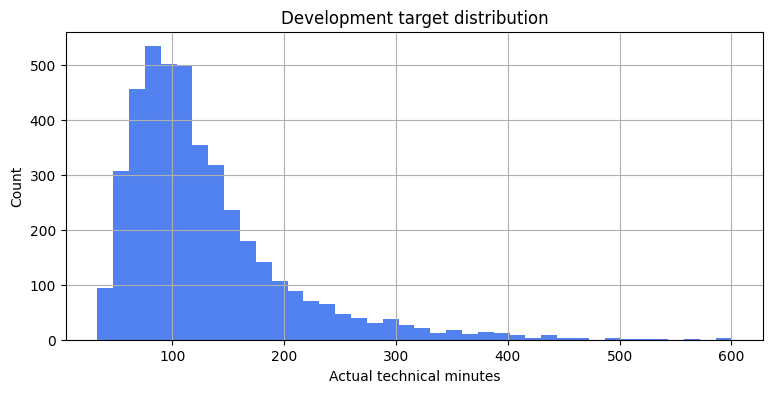

count    4250.00
mean      129.22
std        72.05
min        33.00
50%       110.50
90%       220.00
95%       276.55
max       600.00
Name: actual_technical_minutes, dtype: float64

In [7]:
ax = y_dev.hist(bins=40, figsize=(9, 4), color='#2563eb', alpha=.8)
ax.set(title='Development target distribution', xlabel='Actual technical minutes', ylabel='Count')
plt.show()
y_dev.describe(percentiles=[.5, .9, .95]).round(2)

## 16. Numeric relationships

In [8]:
split.development[NUMERIC_FEATURES + [TARGET]].corr(numeric_only=True).round(3)

,standard_duration_minutes,technician_jobs_completed_before,technician_average_duration_before,technician_issue_experience_before,technician_historical_efficiency_before,actual_technical_minutes
standard_duration_minutes,1.000,-0.004,-0.008,-0.142,-0.004,0.803
technician_jobs_completed_before,-0.004,1.000,0.053,0.723,0.029,-0.013
technician_average_duration_before,-0.008,0.053,1.000,0.034,0.891,0.123
technician_issue_experience_before,-0.142,0.723,0.034,1.000,0.017,-0.165
technician_historical_efficiency_before,-0.004,0.029,0.891,0.017,1.000,0.144
actual_technical_minutes,0.803,-0.013,0.123,-0.165,0.144,1.000


## 17. Category distributions

In [9]:
{column: split.development[column].value_counts().head(8).to_dict()
 for column in ['device_type', 'service_issue', 'service_type', 'technician_id']}

{'device_type': {'iPhone': 2095,
  'MacBook': 662,
  'iPad': 639,
  'AirPods': 465,
  'Apple Watch': 389},
 'service_issue': {'Pin': 1677,
  'Màn hình': 1190,
  'Cổng sạc': 312,
  'Mainboard': 241,
  'Bàn phím': 167,
  'Âm thanh': 133,
  'Hộp sạc': 121,
  'Camera': 116},
 'service_type': {'REPLACEMENT': 2984, 'REPAIR': 922, 'WARRANTY': 344},
 'technician_id': {'TECH_01': 983,
  'TECH_02': 625,
  'TECH_04': 516,
  'TECH_03': 444,
  'TECH_05': 331,
  'TECH_07': 300,
  'TECH_06': 272,
  'TECH_08': 226}}

## 18. Leakage discussion

History uses only `previous_job.completed_at < prediction_timestamp`. Không
`groupby` toàn dataset rồi backfill. Preprocessing được fit trong từng temporal
fold. Holdout 15% cuối chưa được đọc khi tuning và khóa winner.

## 19. Baselines and regression metrics

Mean baseline học $\bar y_{train}$; business baseline dùng
$\hat y=standard\_duration\_minutes$.

$$MAE=\frac1n\sum|y_i-\hat y_i|,\quad
MSE=\frac1n\sum(y_i-\hat y_i)^2,\quad RMSE=\sqrt{MSE}.$$
$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}.$$
Với $AE_i=|y_i-\hat y_i|$, $P90AE=percentile_{90}(\{AE_i\})$; 90% dự đoán có
sai số tuyệt đối không vượt mức này. $R^2$ không phải phần trăm accuracy.

In [10]:
baseline_rows, fold_metrics = _baseline_cv_rows(X_dev, y_dev, folds)
cv_rows = list(baseline_rows)
best_estimators, best_parameters = {}, {}
pd.DataFrame(baseline_rows)

,model,cv_mae_mean,cv_mae_std,cv_mse,cv_rmse,cv_r2,cv_p90_absolute_error,cv_fit_seconds,cv_predict_seconds
0,MeanBaseline,52.743861,1.573270,5203.176976,72.048806,-0.004520,94.742647,0.0,0.0
1,StandardDurationBaseline,30.600294,1.858976,2224.840882,46.993133,0.573752,67.325000,0.0,0.0


## 20. Theory — Random Forest

$$\hat y_{RF}(x)=\frac1B\sum_{b=1}^{B}T_b(x).$$
Mỗi cây học từ bootstrap sample và subset feature ngẫu nhiên. Trung bình nhiều
cây giảm variance. Split hồi quy tối thiểu hóa tổng squared errors hai nút con.

## 21. Train/tune Random Forest

In [11]:
specs = build_model_specs(smoke=False)
name = 'RandomForestRegressor'
est, params, summary, rows, _ = _tune_candidate(name, specs[name], X_dev, y_dev, folds, 8)
best_estimators[name], best_parameters[name], fold_metrics[name] = est, params, rows
cv_rows.append({'model': name, **summary})
params, summary

({'model__n_estimators': 320,
  'model__min_samples_leaf': 6,
  'model__max_features': 0.7,
  'model__max_depth': 14},
 {'cv_mae_mean': 28.17352479910942,
  'cv_mae_std': 1.5511360263173515,
  'cv_mse': 1677.48040397606,
  'cv_rmse': 40.84103026131454,
  'cv_r2': 0.6776235235383523,
  'cv_p90_absolute_error': 59.49180843514109,
  'cv_fit_seconds': 22.82753120000052,
  'cv_predict_seconds': 0.2781448999958229,
  'search_seconds': 266.8849807999977})

## 22. Theory — HistGradientBoosting

$$F_0(x)=initial,\qquad F_m(x)=F_{m-1}(x)+\eta h_m(x).$$
Với squared-error intuition, $r_i^{(m)}=y_i-F_{m-1}(x_i)$ và learner mới học
residual/negative gradient. Histogram binning gom giá trị feature để tìm split
hiệu quả; đó không phải target binning. HGB dùng ordinal dense + native
categorical splits, không nhận sparse one-hot không phù hợp.

## 23. Train/tune HistGradientBoosting

In [12]:
name = 'HistGradientBoostingRegressor'
est, params, summary, rows, _ = _tune_candidate(name, specs[name], X_dev, y_dev, folds, 8)
best_estimators[name], best_parameters[name], fold_metrics[name] = est, params, rows
cv_rows.append({'model': name, **summary})
params, summary

({'model__min_samples_leaf': 30,
  'model__max_leaf_nodes': 31,
  'model__max_iter': 160,
  'model__learning_rate': 0.04,
  'model__l2_regularization': 1.0},
 {'cv_mae_mean': 27.235749329064582,
  'cv_mae_std': 1.1633601828310445,
  'cv_mse': 1650.75903288693,
  'cv_rmse': 40.493145076340454,
  'cv_r2': 0.6832110391271848,
  'cv_p90_absolute_error': 57.65111736769044,
  'cv_fit_seconds': 3.0812837000012223,
  'cv_predict_seconds': 0.1944575000052282,
  'search_seconds': 25.15802789999725})

## 24. Theory — XGBoost

$$Obj^{(t)}=\sum_i l(y_i,\hat y_i^{(t-1)}+f_t(x_i))+\Omega(f_t),$$
$$\Omega(f)=\gamma T+\frac12\lambda\lVert w\rVert^2.$$
XGBoost dùng Taylor bậc hai với
$g_i=\partial l/\partial\hat y_i$ và
$h_i=\partial^2l/\partial\hat y_i^2$. $T$ là số leaf; $w$ là leaf weights;
$\gamma,\lambda$ kiểm soát độ phức tạp. Row/feature subsampling giúp regularize.

## 25. Train/tune XGBoost

In [13]:
name = 'XGBRegressor'
est, params, summary, rows, _ = _tune_candidate(name, specs[name], X_dev, y_dev, folds, 8)
best_estimators[name], best_parameters[name], fold_metrics[name] = est, params, rows
cv_rows.append({'model': name, **summary})
params, summary

({'model__subsample': 0.8,
  'model__reg_lambda': 1.0,
  'model__reg_alpha': 0.2,
  'model__n_estimators': 200,
  'model__min_child_weight': 5,
  'model__max_depth': 4,
  'model__learning_rate': 0.035,
  'model__colsample_bytree': 0.8},
 {'cv_mae_mean': 27.220469192056093,
  'cv_mae_std': 1.280937811669469,
  'cv_mse': 1678.520696173989,
  'cv_rmse': 40.84300992921894,
  'cv_r2': 0.6778040510059511,
  'cv_p90_absolute_error': 56.937091064453135,
  'cv_fit_seconds': 0.8805281999993895,
  'cv_predict_seconds': 0.06869449999794597,
  'search_seconds': 10.614366400001018})

## 26. Theory — CatBoost

CatBoost là gradient-boosted trees với xử lý categorical native. Ordered target
statistic minh họa có smoothing:

$$TS_i=\frac{\sum_{j:\sigma(j)<\sigma(i)}\mathbf1[x_j=x_i]y_j+aP}
{\sum_{j:\sigma(j)<\sigma(i)}\mathbf1[x_j=x_i]+a}.$$

$\sigma$ là permutation, $P$ là prior, $a$ là smoothing. Mẫu hiện tại không
dùng trực tiếp target của chính nó để encode category. Đây là nguyên lý minh
họa, không phải toàn bộ thuật toán CatBoost; ordered boosting tiếp tục giảm
prediction shift/leakage.

## 27. Train/tune CatBoost

In [14]:
name = 'CatBoostRegressor'
est, params, summary, rows, _ = _tune_candidate(name, specs[name], X_dev, y_dev, folds, 8)
best_estimators[name], best_parameters[name], fold_metrics[name] = est, params, rows
cv_rows.append({'model': name, **summary})
params, summary

({'random_strength': 1.0,
  'learning_rate': 0.035,
  'l2_leaf_reg': 8.0,
  'iterations': 240,
  'depth': 5},
 {'cv_mae_mean': 27.16679080615067,
  'cv_mae_std': 1.106630160064843,
  'cv_mse': 1689.8806671118155,
  'cv_rmse': 40.99310317943454,
  'cv_r2': 0.6754035630554561,
  'cv_p90_absolute_error': 58.64250384061903,
  'cv_fit_seconds': 42.816467000004195,
  'cv_predict_seconds': 0.044740199999068864,
  'search_seconds': 707.9054179000013})

## 28. Temporal CV comparison

In [15]:
cv_table = pd.DataFrame(cv_rows).sort_values('cv_mae_mean').reset_index(drop=True)
cv_table[['model','cv_mae_mean','cv_mae_std','cv_mse','cv_rmse','cv_r2','cv_p90_absolute_error']].round(3)

,model,cv_mae_mean,cv_mae_std,cv_mse,cv_rmse,cv_r2,cv_p90_absolute_error
0,CatBoostRegressor,27.167,1.107,1689.881,40.993,0.675,58.643
1,XGBRegressor,27.220,1.281,1678.521,40.843,0.678,56.937
2,HistGradientBoostingRegressor,27.236,1.163,1650.759,40.493,0.683,57.651
3,RandomForestRegressor,28.174,1.551,1677.480,40.841,0.678,59.492
4,StandardDurationBaseline,30.600,1.859,2224.841,46.993,0.574,67.325
5,MeanBaseline,52.744,1.573,5203.177,72.049,-0.005,94.743


## 29. Lock winner

Winner dùng development CV MAE. Chênh ≤0,25 phút là near tie; lần lượt xét
CV-MAE std, RMSE, P90AE và complexity. Test chưa tham gia quyết định.

In [16]:
winner_name, winner_reason = select_winner(cv_table); (winner_name, winner_reason)

('CatBoostRegressor',
 'Models within 0.25 minute of the best CV MAE were treated as a practical tie (CatBoostRegressor, XGBRegressor, HistGradientBoostingRegressor). CatBoostRegressor was locked using, in order, lower CV-MAE standard deviation, CV RMSE, CV P90 absolute error and implementation-complexity rank. The test set was not consulted.')

## 30. Untouched test evaluation

In [17]:
test_rows = []
from repair_duration_ml.evaluation import regression_metrics
mean_pred = np.full(len(y_test), y_dev.mean())
std_pred = X_test.standard_duration_minutes.to_numpy(float)
test_rows += [
    {'model':'MeanBaseline', **regression_metrics(y_test, mean_pred), 'fit_seconds':0., 'predict_seconds':0.},
    {'model':'StandardDurationBaseline', **regression_metrics(y_test, std_pred), 'fit_seconds':0., 'predict_seconds':0.},
]
fitted_models, predictions = {}, {}
for name in MODEL_NAMES:
    fitted, pred, metrics = _test_candidate(best_estimators[name], X_dev, y_dev, X_test, y_test)
    fitted_models[name], predictions[name] = fitted, pred
    test_rows.append({'model': name, **metrics})
test_table = pd.DataFrame(test_rows).sort_values('mae').reset_index(drop=True)
winner_estimator, winner_predictions = fitted_models[winner_name], predictions[winner_name]
test_table.round(3)

,model,mae,mse,rmse,r2,p90_absolute_error,fit_seconds,predict_seconds
0,HistGradientBoostingRegressor,26.992,1796.148,42.381,0.658,55.923,0.739,0.040
1,CatBoostRegressor,27.009,1800.907,42.437,0.657,56.075,11.538,0.008
2,XGBRegressor,27.017,1809.833,42.542,0.655,55.932,0.347,0.015
3,RandomForestRegressor,27.745,1715.280,41.416,0.673,58.622,13.950,0.067
4,StandardDurationBaseline,31.215,2516.527,50.165,0.520,73.100,0.000,0.000
5,MeanBaseline,52.034,5258.109,72.513,-0.002,93.324,0.000,0.000


## 31. Actual vs Predicted

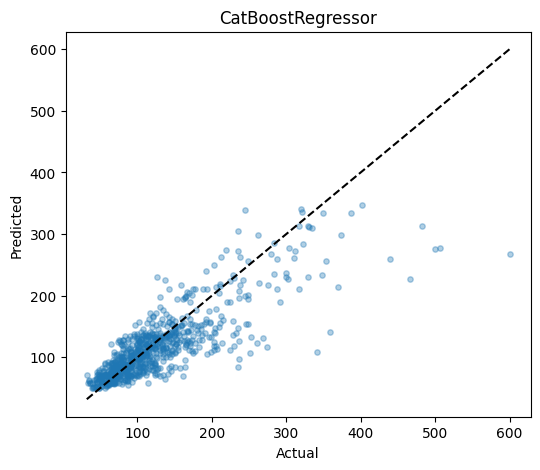

In [18]:
plt.figure(figsize=(6,5)); plt.scatter(y_test, winner_predictions, alpha=.35, s=15)
lo=min(y_test.min(), winner_predictions.min()); hi=max(y_test.max(), winner_predictions.max())
plt.plot([lo,hi],[lo,hi],'k--'); plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title(winner_name); plt.show()

## 32. Residual analysis

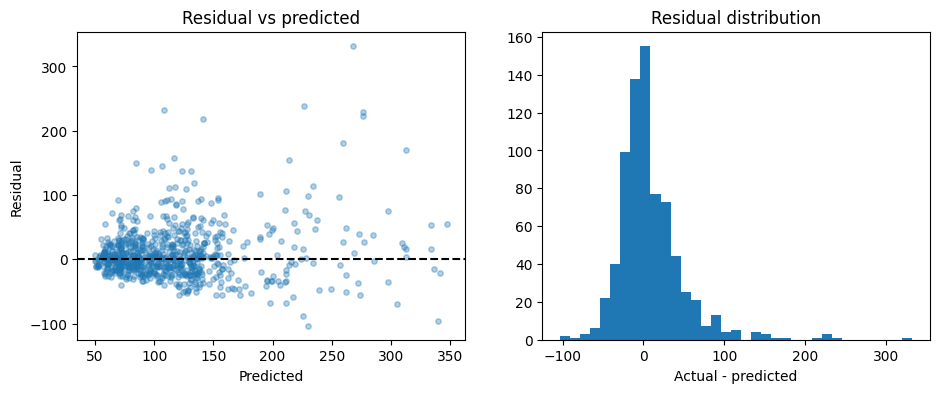

count    750.00
mean       8.90
std       41.52
min     -103.30
25%      -14.53
50%        1.85
75%       23.45
max      332.24
dtype: float64

In [19]:
residual = y_test.to_numpy() - winner_predictions
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(winner_predictions,residual,alpha=.35,s=15); ax[0].axhline(0,color='k',ls='--')
ax[0].set(xlabel='Predicted',ylabel='Residual',title='Residual vs predicted')
ax[1].hist(residual,bins=35); ax[1].set(title='Residual distribution',xlabel='Actual - predicted')
plt.show()
pd.Series(residual).describe().round(2)

## 33. P90 absolute-error analysis

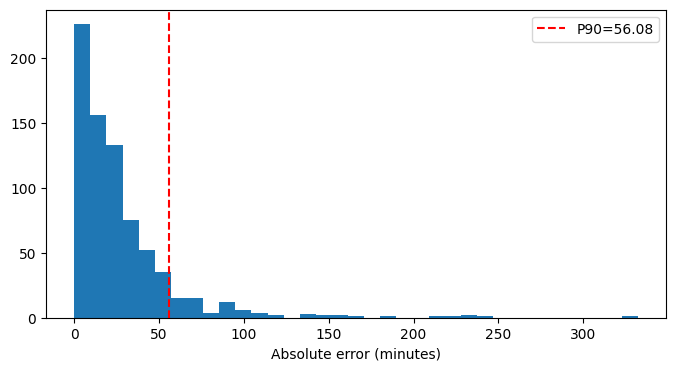

np.float64(56.07519935421155)

In [20]:
absolute_error = np.abs(residual); p90 = np.percentile(absolute_error,90)
plt.figure(figsize=(8,4)); plt.hist(absolute_error,bins=35); plt.axvline(p90,color='red',ls='--',label=f'P90={p90:.2f}')
plt.legend(); plt.xlabel('Absolute error (minutes)'); plt.show(); p90

## 34. Subgroup errors

In [21]:
subgroups = {c: subgroup_errors(split.test, winner_predictions, c)
             for c in ['technician_id','device_type','service_issue','service_type']}
{c: pd.DataFrame(rows).head(8) for c, rows in subgroups.items()}

{'technician_id':      group  sample_count        mae       rmse
 0  TECH_09            45  35.743180  58.289230
 1  TECH_07            83  34.074031  50.675158
 2  TECH_02            61  31.357898  43.288255
 3  TECH_06            52  30.990734  56.296308
 4  TECH_04            70  30.244085  45.563284
 5  TECH_12            45  27.526811  49.710154
 6  TECH_01            71  26.597133  36.869302
 7  TECH_05            71  24.912951  35.437809,
 'device_type':          group  sample_count        mae       rmse
 0      MacBook           106  38.982990  54.634849
 1         iPad           114  33.730421  44.407014
 2       iPhone           360  23.687972  40.777915
 3      AirPods            98  23.489597  38.385586
 4  Apple Watch            72  20.138444  30.378927,
 'service_issue':            group  sample_count        mae       rmse
 0      Mainboard            35  64.937348  97.957021
 1       Bàn phím            30  51.299705  70.850177
 2       Chống ồn            17  34.639197 

## 35. Feature importance and explainability

Permutation importance đo mức MAE tăng khi xáo trộn một feature trên holdout.
Importance cho biết giá trị dự báo của model, **không chứng minh quan hệ nhân quả**.

In [22]:
pd.DataFrame(feature_importance(winner_estimator, X_test, y_test)).head(14).round(3)

,feature,importance_mean_mae_increase,importance_std
0,standard_duration_minutes,23.818,0.723
1,service_type,2.022,0.340
2,technician_historical_efficiency_before,0.946,0.155
3,device_type,0.780,0.128
4,technician_id,0.471,0.100
5,service_issue,0.441,0.109
6,catalog_service,0.334,0.128
7,technician_average_duration_before,0.119,0.049
8,device_model,0.113,0.062
9,technician_jobs_completed_before,0.039,0.014


## 36. Cold-start predictions

In [23]:
cold = cold_start_examples(X_dev)
pd.DataFrame({'scenario':cold.index, 'prediction':winner_estimator.predict(cold)})

,scenario,prediction
0,known_history,122.366656
1,new_technician,111.801703
2,unseen_categories,113.429776


## 37. Example new-job prediction

In [24]:
example = cold.loc[['new_technician']]
{'input': example.to_dict(orient='records')[0],
 'predicted_technical_minutes': float(winner_estimator.predict(example)[0])}

{'input': {'device_type': 'Apple Watch',
  'device_model': 'Apple Watch Series 9',
  'service_issue': 'Sạc không dây',
  'service_type': 'REPAIR',
  'catalog_service': 'Sửa sạc Apple Watch Series 9',
  'standard_duration_minutes': 105,
  'technician_id': 'TECH_NEW',
  'branch_id': 'BRANCH_01',
  'prediction_month': 'M06',
  'prediction_weekday': 'THU',
  'technician_jobs_completed_before': 0,
  'technician_average_duration_before': nan,
  'technician_issue_experience_before': 0,
  'technician_historical_efficiency_before': nan},
 'predicted_technical_minutes': 111.80170297379907}

## 38. Relationship to ETA

Prediction là active technical minutes. ETA engine tương lai mới kết hợp queue,
working schedule, break, current state và interruption semantics đã được chốt.
Phase này không ghi prediction vào Spring/MySQL và không đổi ETA hiện tại.

## 39. Limitations

- synthetic distribution không chứng minh generalization ngoài thực tế;
- grain loại multi-item/transfer/incomplete history;
- persisted interruptions chưa được production duration service trừ;
- catalog là controlled synthetic catalog, không phải snapshot master thật;
- subgroup nhỏ phải đọc cùng sample count;
- permutation importance không phải causality.

## 40. Next production-data phase

MySQL snapshot → leakage-safe real extractor → `real_repair_duration_vX` → cùng
feature contract/training pipeline → real temporal holdout → explicit approval
→ mới xem xét runtime integration.

## 41. Final conclusion

Notebook khóa winner tự động bằng development temporal CV và chỉ sau đó mở
holdout. Kết luận phải đọc từ output thực tế phía trên. Artifact CLI vẫn là
**experimental, synthetic-data trained, not production validated**.